In [1]:
import json
from pathlib import Path

import pandas as pd
from google.colab import drive
from IPython.display import display

project_dir = Path("/content/drive/MyDrive/AgroVision_FYP2")
if not project_dir.is_dir():
    drive.mount("/content/drive")

mapping_dir = project_dir / "mapping_results"
label_path = project_dir / "plantvillage_preparation" / "class_to_index.json"

with label_path.open(encoding="utf-8") as file:
    class_to_index = json.load(file)

assert len(class_to_index) == 38
assert set(class_to_index.values()) == set(range(38))

plantdoc_mapping = pd.read_csv(mapping_dir / "plantdoc_final_mapping.csv")
plantdoc_inventory = pd.read_csv(
    project_dir / "plantdoc_preparation" / "plantdoc_test_inventory.csv"
)
fieldplant_mapping = pd.read_csv(mapping_dir / "fieldplant_approved_mapping.csv")
fieldplant_inventory = pd.read_csv(
    project_dir / "fieldplant_preparation" / "fieldplant_crop_inventory.csv"
)

assert len(plantdoc_mapping) == 28
assert len(fieldplant_mapping) == 4
assert fieldplant_mapping["mapping_category"].eq("Direct match").all()

plantdoc_folders = plantdoc_inventory["filepath"].map(lambda path: Path(path).parent)
assert plantdoc_folders.map(lambda folder: folder.parent.name).eq("test").all()
assert plantdoc_folders.map(lambda folder: folder.name).eq(
    plantdoc_inventory["plantdoc_class"]
).all()

assert fieldplant_inventory["source_image_filepath"].nunique() == 289

datasets = [
    ("PlantDoc", plantdoc_mapping, plantdoc_inventory,
     "class_name", "plantdoc_class", "filepath", "test_images", 236, 27),
    ("FieldPlant", fieldplant_mapping, fieldplant_inventory,
     "class_id", "fieldplant_class_id", "crop_filepath", "annotated_objects", 504, 4),
]

for name, mapping, inventory, map_key, sample_key, path_col, count_col, n, k in datasets:
    assert len(inventory) == n, f"{name}: unexpected sample count"
    assert inventory[path_col].notna().all() and inventory[path_col].is_unique
    assert mapping[map_key].notna().all() and mapping[map_key].is_unique
    assert mapping["plantvillage_class"].is_unique
    assert mapping["plantvillage_class"].isin(class_to_index).all()

    lookup = mapping.set_index(map_key)["plantvillage_class"]
    mapped_labels = inventory[sample_key].map(lookup)
    assert mapped_labels.notna().all(), f"{name}: unmapped source labels"
    assert mapped_labels.eq(inventory["plantvillage_class"]).all(), (
        f"{name}: inventory labels disagree with the mapping table"
    )

    audit = mapping[["class_name", "plantvillage_class", "mapping_category"]].copy()
    audit["class_index"] = audit["plantvillage_class"].map(class_to_index)
    audit["expected"] = mapping[count_col]
    audit["observed"] = mapping[map_key].map(
        inventory[sample_key].value_counts()
    ).fillna(0).astype(int)

    assert audit["expected"].eq(audit["observed"]).all(), (
        f"{name}: per-class counts differ from the mapping table"
    )
    assert audit["observed"].gt(0).sum() == k

    print(f"\n{name} | {n} samples | {k} represented classes")
    display(audit)

print("\nPASS: Saved class mappings and inventory counts agree.")

Mounted at /content/drive

PlantDoc | 236 samples | 27 represented classes


,class_name,plantvillage_class,mapping_category,class_index,expected,observed
0,Apple Scab Leaf,Apple___Apple_scab,Direct match,0,10,10
1,Apple leaf,Apple___healthy,Defensible match,3,9,9
2,Apple rust leaf,Apple___Cedar_apple_rust,Defensible match,2,10,10
3,Bell_pepper leaf,"Pepper,_bell___healthy",Defensible match,19,8,8
4,Bell_pepper leaf spot,"Pepper,_bell___Bacterial_spot",Defensible match,18,9,9
5,Blueberry leaf,Blueberry___healthy,Defensible match,4,11,11
6,Cherry leaf,Cherry_(including_sour)___healthy,Defensible match,6,10,10
7,Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Direct match,7,4,4
8,Corn leaf blight,Corn_(maize)___Northern_Leaf_Blight,Direct match,9,12,12
9,Corn rust leaf,Corn_(maize)___Common_rust_,Direct match,8,10,10



FieldPlant | 504 samples | 4 represented classes


,class_name,plantvillage_class,mapping_category,class_index,expected,observed
0,Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Direct match,7,54,54
1,Corn Healthy,Corn_(maize)___healthy,Direct match,10,152,152
2,Tomato healthy,Tomato___healthy,Direct match,37,279,279
3,Tomato leaf mosaic virus,Tomato___Tomato_mosaic_virus,Direct match,36,19,19



PASS: Saved class mappings and inventory counts agree.


In [3]:
import numpy as np
from sklearn.metrics import f1_score

external_dir = (
    project_dir
    / "augmentation_retraining"
    / "enhanced_v1"
    / "EfficientNetB0"
    / "evaluation"
    / "external"
)
saved_metrics = pd.read_csv(
    external_dir / "external_dataset_metrics.csv"
).set_index("dataset", verify_integrity=True)

verified_predictions = {}
summary = []

for name, _, inventory, _, _, path_col, _, n, k in datasets:
    ordered = inventory.sort_values(path_col)
    expected_paths = ordered[path_col].to_numpy(dtype=str)
    expected_classes = ordered["plantvillage_class"].to_numpy(dtype=str)
    expected_labels = ordered["plantvillage_class"].map(class_to_index).to_numpy()
    expected_sources = (
        ordered["source_image_filepath"].to_numpy(dtype=str)
        if name == "FieldPlant"
        else expected_paths
    )

    with np.load(external_dir / f"{name}_predictions.npz", allow_pickle=False) as saved:
        for key, expected in [
            ("filepaths", expected_paths),
            ("source_image_filepaths", expected_sources),
            ("true_classes", expected_classes),
            ("true_labels", expected_labels),
        ]:
            np.testing.assert_array_equal(
                saved[key], expected, err_msg=f"{name}: {key} mismatch"
            )

        y_true = saved["true_labels"]
        y_pred = saved["predicted_labels"]
        probabilities = saved["probabilities"]

    assert probabilities.shape == (n, 38), f"{name}: unexpected output shape"
    assert np.isfinite(probabilities).all(), f"{name}: non-finite scores"
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-3)
    np.testing.assert_array_equal(y_pred, probabilities.argmax(axis=1))

    represented = np.unique(y_true)
    assert len(represented) == k

    correct = int((y_true == y_pred).sum())
    outside = int((~np.isin(y_pred, represented)).sum())
    accuracy = correct / n
    macro_f1 = f1_score(y_true, y_pred, labels=represented, average="macro", zero_division=0)
    weighted_f1 = f1_score(
        y_true, y_pred, labels=represented, average="weighted", zero_division=0
    )

    recorded = saved_metrics.loc[f"Cropped-{name}"]
    assert int(recorded["correct_predictions"]) == correct
    assert int(recorded["predictions_outside_coverage"]) == outside
    for metric, value in [
        ("accuracy", accuracy),
        ("macro_f1", macro_f1),
        ("weighted_f1", weighted_f1),
    ]:
        np.testing.assert_allclose(
            value, recorded[metric], atol=1e-8, rtol=0,
            err_msg=f"{name}: {metric} mismatch",
        )

    verified_predictions[name] = (y_true, y_pred)
    summary.append({
        "Dataset": name,
        "Samples": n,
        "Correct": correct,
        "Accuracy (%)": round(100 * accuracy, 2),
        "Macro F1 (%)": round(100 * macro_f1, 2),
        "Weighted F1 (%)": round(100 * weighted_f1, 2),
        "Predictions outside test coverage": outside,
    })

display(pd.DataFrame(summary))
print("PASS: Prediction rows, class indices and saved metrics agree.")

,Dataset,Samples,Correct,Accuracy (%),Macro F1 (%),Weighted F1 (%),Predictions outside test coverage
0,PlantDoc,236,64,27.12,25.21,24.59,33
1,FieldPlant,504,160,31.75,38.65,37.16,312


PASS: Prediction rows, class indices and saved metrics agree.


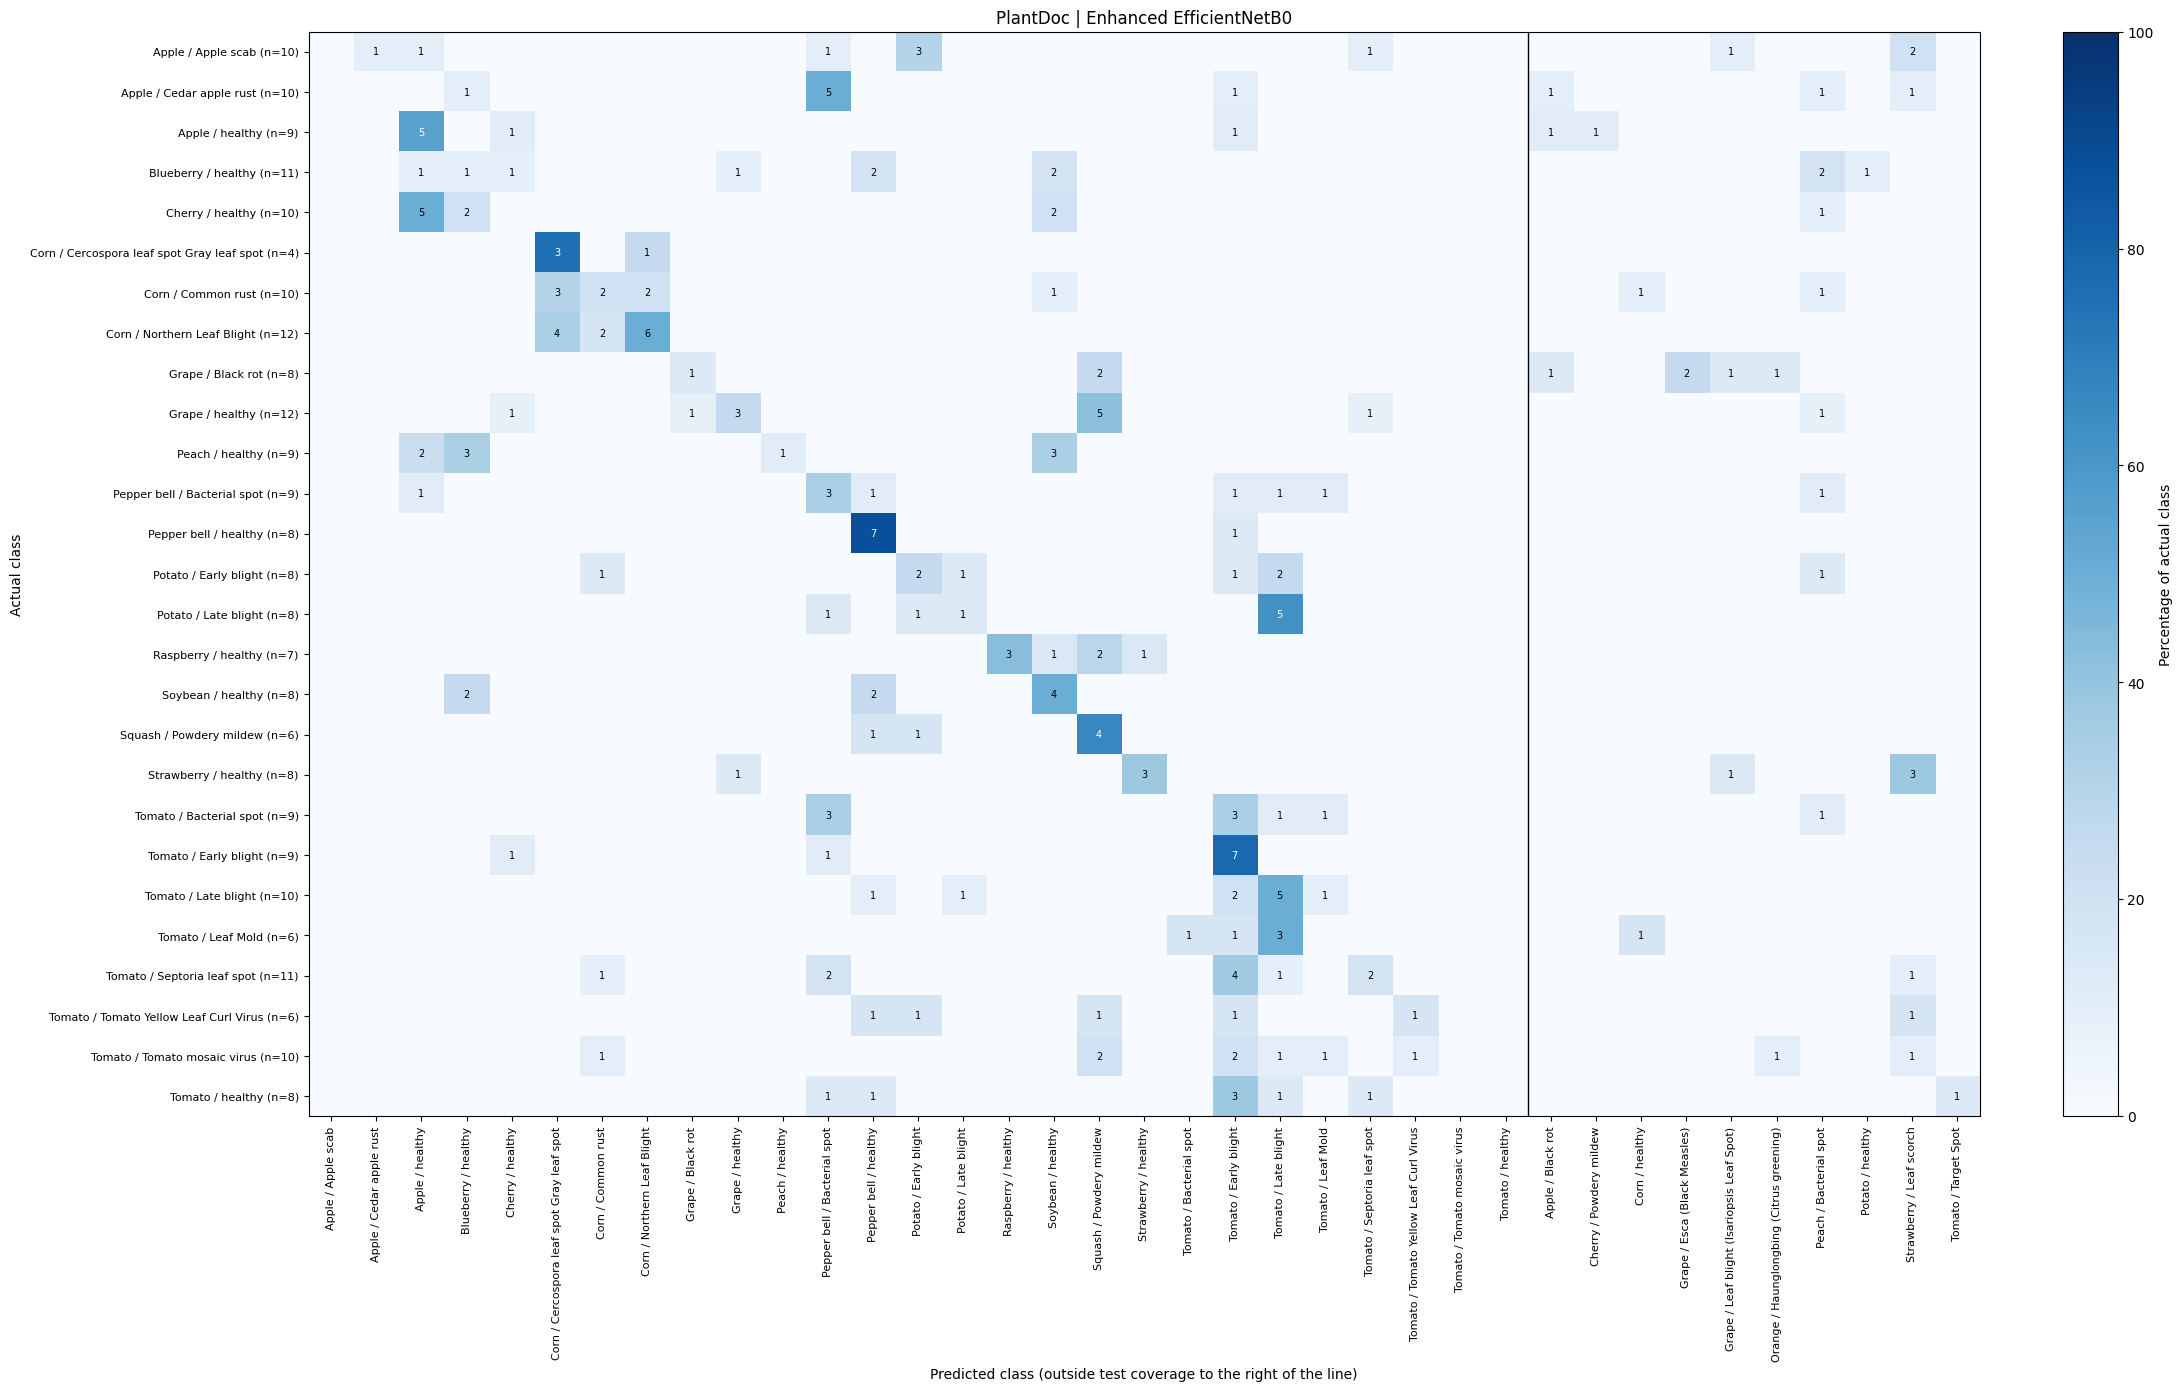


PlantDoc | 236 samples | 64 correct | 172 errors | 33 outside test coverage
Most frequent errors
  Apple / Cedar apple rust → Pepper bell / Bacterial spot | 5 of 10
  Cherry / healthy → Apple / healthy | 5 of 10
  Grape / healthy → Squash / Powdery mildew | 5 of 12
  Potato / Late blight → Tomato / Late blight | 5 of 8
  Corn / Northern Leaf Blight → Corn / Cercospora leaf spot Gray leaf spot | 4 of 12


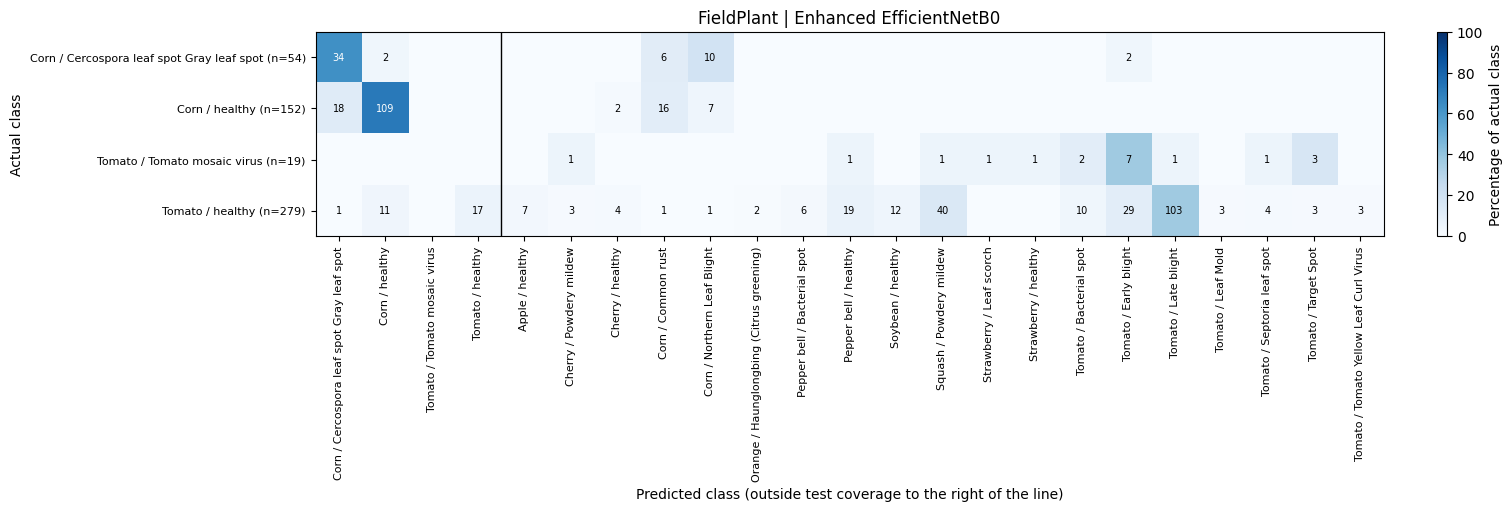


FieldPlant | 504 samples | 160 correct | 344 errors | 312 outside test coverage
Most frequent errors
  Tomato / healthy → Tomato / Late blight | 103 of 279
  Tomato / healthy → Squash / Powdery mildew | 40 of 279
  Tomato / healthy → Tomato / Early blight | 29 of 279
  Tomato / healthy → Pepper bell / healthy | 19 of 279
  Corn / healthy → Corn / Cercospora leaf spot Gray leaf spot | 18 of 152

Saved figures and count tables to /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/evaluation/external/phase6_final_verification


In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

output_dir = external_dir / "phase6_final_verification"
output_dir.mkdir(exist_ok=True)

class_ids = np.arange(len(class_to_index))
class_names = sorted(class_to_index, key=class_to_index.get)


def readable_label(class_id):
    crop, condition = class_names[class_id].split("___", maxsplit=1)
    crop = crop.replace("_(maize)", "").replace("_(including_sour)", "")
    crop = crop.replace(",_", "_").replace("_", " ")
    condition = condition.replace("_", " ").strip()
    return f"{crop} / {condition}"


for name, (y_true, y_pred) in verified_predictions.items():
    full_matrix = confusion_matrix(y_true, y_pred, labels=class_ids)
    represented = np.unique(y_true)
    actual_matrix = full_matrix[represented, :]
    support = actual_matrix.sum(axis=1)
    correct = int(np.trace(full_matrix))

    outside_classes = np.setdiff1d(class_ids, represented)
    outside_count = int(actual_matrix[:, outside_classes].sum())

    assert actual_matrix.sum() == len(y_true)
    assert correct == np.count_nonzero(y_true == y_pred)
    assert outside_count == np.count_nonzero(~np.isin(y_pred, represented))

    # Export all 38 prediction columns, including those with zero predictions.
    matrix_table = pd.DataFrame(
        actual_matrix,
        index=[class_names[i] for i in represented],
        columns=class_names,
    )
    matrix_table.index.name = "actual_class"
    matrix_table.to_csv(output_dir / f"{name}_confusion_matrix_counts.csv")

    # Plot the represented classes and every outside class the model predicted.
    observed_outside = outside_classes[actual_matrix[:, outside_classes].any(axis=0)]
    shown_classes = np.concatenate([represented, observed_outside])
    counts = actual_matrix[:, shown_classes]
    percentages = 100 * counts / support[:, None]
    assert counts.sum() == len(y_true)

    fig, ax = plt.subplots(
        figsize=(
            max(11, 0.48 * len(shown_classes) + 4),
            max(5, 0.40 * len(represented) + 3),
        ),
        layout="constrained",
    )

    heatmap = ax.imshow(percentages, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    fig.colorbar(heatmap, ax=ax, label="Percentage of actual class")

    ax.set_xticks(
        np.arange(len(shown_classes)),
        [readable_label(i) for i in shown_classes],
        rotation=90,
        fontsize=8,
    )
    ax.set_yticks(
        np.arange(len(represented)),
        [f"{readable_label(i)} (n={total})" for i, total in zip(represented, support)],
        fontsize=8,
    )
    ax.axvline(len(represented) - 0.5, color="black", linewidth=1)
    ax.set_title(f"{name} | Enhanced EfficientNetB0")
    ax.set_xlabel("Predicted class (outside test coverage to the right of the line)")
    ax.set_ylabel("Actual class")

    for row, col in np.argwhere(counts > 0):
        ax.text(
            col,
            row,
            str(counts[row, col]),
            ha="center",
            va="center",
            fontsize=7,
            color="white" if percentages[row, col] >= 55 else "black",
        )

    fig.savefig(output_dir / f"{name}_confusion_matrix.png", dpi=180)
    plt.show()
    plt.close(fig)

    errors = full_matrix.copy()
    np.fill_diagonal(errors, 0)
    pairs = sorted(np.argwhere(errors > 0), key=lambda pair: -errors[tuple(pair)])

    print(
        f"\n{name} | {len(y_true)} samples | {correct} correct | "
        f"{len(y_true) - correct} errors | {outside_count} outside test coverage"
    )
    print("Most frequent errors")
    for actual, predicted in pairs[:5]:
        print(
            f"  {readable_label(actual)} → {readable_label(predicted)} | "
            f"{errors[actual, predicted]} of {full_matrix[actual].sum()}"
        )

print(f"\nSaved figures and count tables to {output_dir}")

In [7]:
from sklearn.metrics import precision_recall_fscore_support

for name, (y_true, y_pred) in verified_predictions.items():
    represented = np.unique(y_true)
    labels = [class_names[i] for i in represented]

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=represented,
        zero_division=0,
    )
    correct = np.bincount(
        y_true[y_true == y_pred], minlength=len(class_names)
    )[represented]
    predicted = np.bincount(
        y_pred, minlength=len(class_names)
    )[represented]
    outside = np.bincount(
        y_true[~np.isin(y_pred, represented)], minlength=len(class_names)
    )[represented]

    counts = pd.read_csv(
        output_dir / f"{name}_confusion_matrix_counts.csv",
        index_col="actual_class",
    )
    np.testing.assert_array_equal(counts.loc[labels].sum(axis=1), support)
    np.testing.assert_array_equal(counts.loc[:, labels].sum(axis=0), predicted)
    np.testing.assert_array_equal(
        np.diag(counts.loc[labels, labels].to_numpy()), correct
    )

    recorded = saved_metrics.loc[f"Cropped-{name}"]
    np.testing.assert_allclose(f1.mean(), recorded["macro_f1"], atol=1e-8, rtol=0)
    np.testing.assert_allclose(
        np.average(f1, weights=support), recorded["weighted_f1"], atol=1e-8, rtol=0
    )

    report = pd.DataFrame({
        "class_index": represented,
        "class_name": labels,
        "support": support,
        "predicted": predicted,
        "correct": correct,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "outside_coverage_errors": outside,
    })
    report.to_csv(output_dir / f"{name}_class_metrics.csv", index=False)

    table = report.copy()
    table["class_name"] = [readable_label(i) for i in represented]
    for metric in ["precision", "recall", "f1"]:
        table[metric] = table[metric].map(lambda value: f"{value:.2%}")

    print(f"\n{name} | {len(report)} classes | {support.sum()} test samples")
    with pd.option_context("display.max_rows", 40, "display.max_colwidth", None):
        display(table)

    print("Classes with zero recall")
    for class_id, total in zip(represented[correct == 0], support[correct == 0]):
        print(f"  {readable_label(class_id)} | 0 of {total} correct")

print("\nPASS: Class counts match the confusion matrices and F1 averages match Cell 2.")


PlantDoc | 27 classes | 236 test samples


,class_index,class_name,support,predicted,correct,precision,recall,f1,outside_coverage_errors
0,0,Apple / Apple scab,10,0,0,0.00%,0.00%,0.00%,3
1,2,Apple / Cedar apple rust,10,1,0,0.00%,0.00%,0.00%,3
2,3,Apple / healthy,9,15,5,33.33%,55.56%,41.67%,2
3,4,Blueberry / healthy,11,9,1,11.11%,9.09%,10.00%,3
4,6,Cherry / healthy,10,4,0,0.00%,0.00%,0.00%,1
5,7,Corn / Cercospora leaf spot Gray leaf spot,4,10,3,30.00%,75.00%,42.86%,0
6,8,Corn / Common rust,10,7,2,28.57%,20.00%,23.53%,2
7,9,Corn / Northern Leaf Blight,12,9,6,66.67%,50.00%,57.14%,0
8,11,Grape / Black rot,8,2,1,50.00%,12.50%,20.00%,5
9,14,Grape / healthy,12,5,3,60.00%,25.00%,35.29%,1


Classes with zero recall
  Apple / Apple scab | 0 of 10 correct
  Apple / Cedar apple rust | 0 of 10 correct
  Cherry / healthy | 0 of 10 correct
  Tomato / Bacterial spot | 0 of 9 correct
  Tomato / Leaf Mold | 0 of 6 correct
  Tomato / Tomato mosaic virus | 0 of 10 correct
  Tomato / healthy | 0 of 8 correct

FieldPlant | 4 classes | 504 test samples


,class_index,class_name,support,predicted,correct,precision,recall,f1,outside_coverage_errors
0,7,Corn / Cercospora leaf spot Gray leaf spot,54,53,34,64.15%,62.96%,63.55%,18
1,10,Corn / healthy,152,122,109,89.34%,71.71%,79.56%,25
2,36,Tomato / Tomato mosaic virus,19,0,0,0.00%,0.00%,0.00%,19
3,37,Tomato / healthy,279,17,17,100.00%,6.09%,11.49%,250


Classes with zero recall
  Tomato / Tomato mosaic virus | 0 of 19 correct

PASS: Class counts match the confusion matrices and F1 averages match Cell 2.


## Phase 6: Final Verification Summary and Conclusion

### Verification Results

The final verification confirmed that the saved class mappings, evaluation inventories, prediction labels and reported metrics were consistent for both external datasets.

- **PlantDoc:** 236 images across 27 represented classes, with 27.12% accuracy and 25.21% macro F1-score.
- **FieldPlant:** 504 cropped leaf images across 4 represented classes, with 31.75% accuracy and 38.65% macro F1-score.
- All saved prediction labels, class indices and evaluation metrics passed the consistency checks.
- Confusion matrices and class-wise precision, recall and F1-scores were generated using the existing EfficientNetB0 predictions.

### Classification Error Analysis

The results revealed substantial classification difficulties under external field conditions.

- **PlantDoc:** 172 incorrect predictions, including 33 predictions outside the represented classes. Seven classes recorded zero recall.
- **FieldPlant:** 344 incorrect predictions, including 312 predictions outside the four represented classes.
- Tomato healthy was frequently misclassified as Tomato Late Blight (103 cases). Only 17 of 279 healthy tomato samples were correctly classified.
- Tomato Mosaic Virus recorded zero correct predictions among 19 FieldPlant samples.

These findings demonstrate a substantial performance gap between the controlled PlantVillage test set (98.43% accuracy) and the external datasets, indicating limited generalisation to field imagery.

### Limitations

- The mapping verification confirms structural consistency but does not independently establish the biological equivalence of all PlantDoc labels.
- FieldPlant includes multiple cropped leaves from some source photographs; therefore, the 504 samples should not be interpreted as 504 independent photographs.
- Differences in image backgrounds, lighting and disease appearance may contribute to classification errors, although their individual effects were not measured.

### Conclusion

The verification and classification error analysis requested for Phase 6 have been completed. All saved evaluation results passed the implemented consistency checks, and no evaluation error requiring model retraining was identified.

The enhanced EfficientNetB0 model remains the selected final model. The project can proceed to **Phase 7: Grad-CAM Explainability**, while acknowledging the identified external generalisation limitations.